In [1]:
cd /share/nas2/pryder/tumbling_git/

/share/nas2/pryder/tumbling_git


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from schedule_utils import range_finder_general
from skyfield.api import load, EarthSatellite, wgs84
from pc_utils import rect, open_vdif, iq_conversion, pc_and_spectrogram, plotter
from scipy.ndimage import shift

In [3]:
tle_line_1 = '1 61995U 16053M   25035.62796428  .00000095  00000-0  00000-0 0  9998'
tle_line_2 = '2 61995   0.2642  88.1708 0053675 268.4745   3.2920  1.01033442  1106'
target_name = 'intelsat'
ts = load.timescale()
intelsat_tle = EarthSatellite(tle_line_1, tle_line_2, target_name, ts)

In [4]:
# input parameters 
cpi = 128      
bw = 8e6        
Tp = 800e-6    
pri = 19.7e-3
freq = 1295e6
c = 299792458
samp_rate = 16e6
alpha = bw/Tp   
height =cpi # CPI Size
points = int(samp_rate * pri)
infilename = '/share/nas2/pryder/SET_Observations_Test_1/Wednesday/vdifs/TSSat_20250205_lo1_1295MHz_intelsat33e.vdifa' #second vdif
channel = 0

In [5]:
# Open VDIF
pola, header = open_vdif(infilename, channel)
print('VDIF opened.')

# Convert to IQ
iq_samples = iq_conversion(pola)
print('Converted into IQ samples.')

VDIF opened.
Converted into IQ samples.


In [6]:
c = 299792458
ts = load.timescale()
freqs = np.fft.fftfreq(points, d=1/samp_rate) # Used for Fourier Shift RCM correction
startoffset = 0 #int(samp_rate * 100)

In [9]:
overlap = 10000
rough_period = 15.63819999999991
time_of_one_cpi = pri*cpi #in seconds
points_of_one_period = rough_period/time_of_one_cpi * points
number_of_strips = int(points_of_one_period/(overlap)) # number of strips in one period

In [10]:
print(number_of_strips)

195


In [17]:
start_idx = startoffset
end_idx = start_idx + (height * points)
cpi_data = iq_samples[start_idx:end_idx].reshape((height, points))

# Update TLE range rate for the start of this CPI
s_offset = (start_idx / samp_rate)
t_tle = ts.utc(2025, 2, 5, 13, 45, s_offset)
range_rate = range_finder_general(intelsat_tle, t_tle, 'lovell')[1]
tau_dot = range_rate / c

# Create template: baseband * chirp * envelope
t_pulse = np.linspace(0, pri, points, endpoint=False)
template = np.exp(1j * np.pi * alpha * t_pulse**2 * (1 - tau_dot)**2) * rect(t_pulse / (Tp * (1 + tau_dot)))
template_fft = np.fft.fft(template)

cdat_pc = np.zeros((height, points), dtype=complex)

# Pulse Compression
for i in range(height):
    start_sec = i * pri
    pulse_fft = np.fft.fft(cpi_data[i])
    
    # Calculating RCM Correction
    delta_tau = 2 * (range_rate * start_sec) / c     # change in range rate since beginning of CPI, converted to time delay
    rcm_shift = np.exp(1j * 2 * np.pi * freqs * delta_tau)          #applying RCM correction in the frequency domain using linear phase shift corresponding to the change in range delay over the CPI duration
    
    # Pulse Compression and RCM shift
    compressed_pulse = np.fft.ifft(pulse_fft * np.conj(template_fft) * rcm_shift)
    
    # Doppler Phase Correction
    f_d = -2 * range_rate * freq / c
    bulk_phase = np.exp(-1j * 2 * np.pi * f_d * start_sec)
    
    # applying doppler correction
    cdat_pc[i] = compressed_pulse * bulk_phase

In [19]:
power = (np.abs(cdat_pc))**2
incoho_sum = np.sum(power, axis=0)

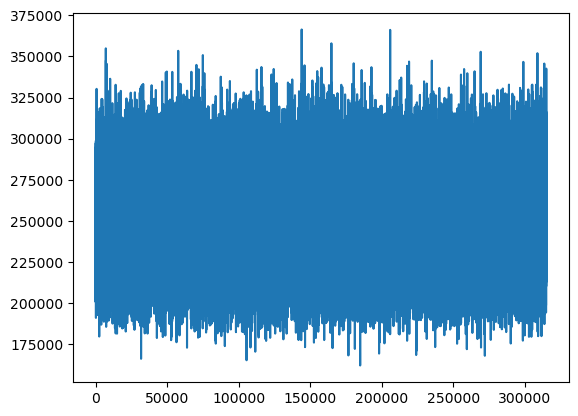

In [ ]:
plt.plot(incoho_sum)
plt.show()
np.save

In [26]:
spectrogram = np.load('./i33e_1000_overlap.npy')
max_velocity = c / (4 * 19.7e-3* (freq))

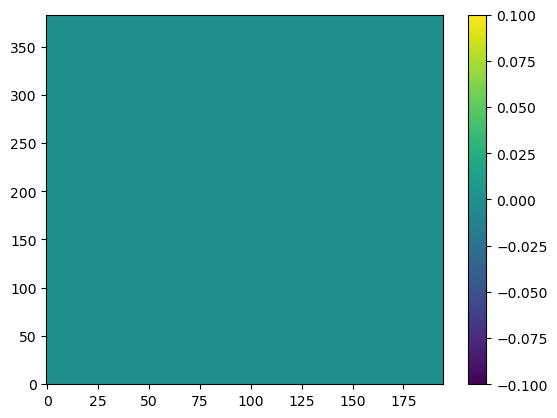

In [30]:
plt.imshow(spectrogram, aspect='auto', origin='lower')
plt.colorbar()
plt.show()

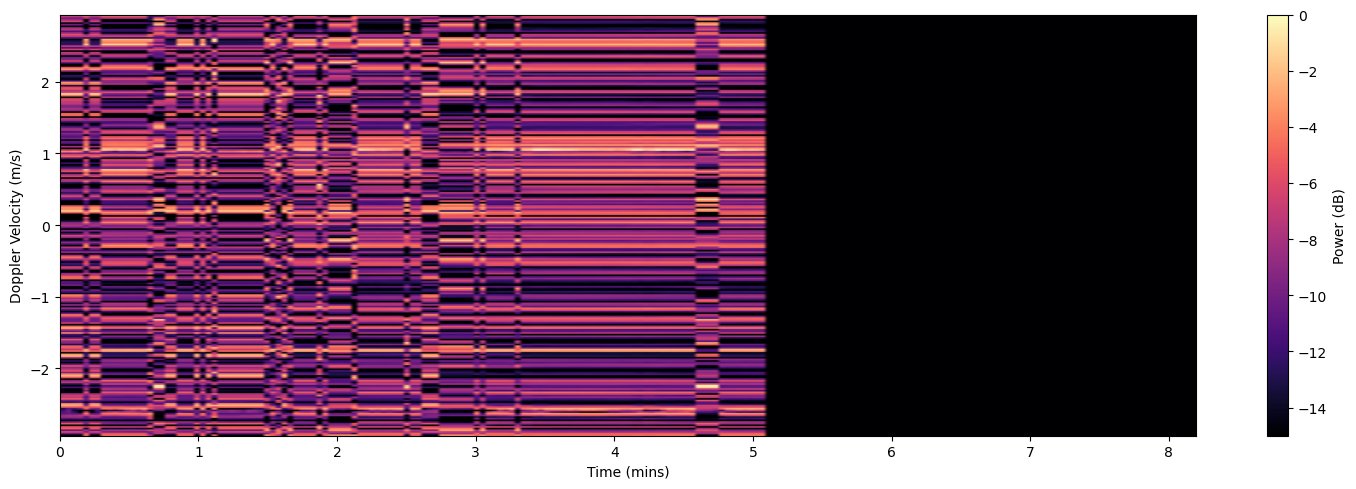

In [ ]:
plt.figure(figsize=(15, 5))
plt.imshow(10 * np.log10(spectrogram+1e-12)-np.max(10 * np.log10(spectrogram+1e-12)), aspect='auto', origin='lower', vmin=-15, vmax=0, extent= [0, 1000/samp_rate*pri, -max_velocity, max_velocity], cmap='magma')
# plt.title("Micro-Doppler Spectrogram")
plt.xlabel("Time (s)")
plt.ylabel("Doppler Velocity (m/s)")
# plt.ylim(-1, 1)
# plt.hlines(int(spectrogram.shape[0]/2+10), 0, 423, 'red')
plt.colorbar(label='Power (dB)')
plt.tight_layout()

In [ ]:
overlap = 10000
rough_period = 15.6
time_of_one_cpi = pri*cpi #in seconds
points_of_one_period = rough_period/time_of_one_cpi * points
number_of_strips = int(points_of_one_period/(overlap)) # number of strips in one period
print(number_of_strips)
spectrogram = np.zeros((height*2, number_of_strips))

for n in range(number_of_strips):
    print(n)
    start_idx = startoffset + (n*overlap)
    end_idx = start_idx + (height * points)
    cpi_data = iq_samples[start_idx:end_idx].reshape((height, points))

    # Update TLE range rate for the start of this CPI
    s_offset = (start_idx / samp_rate) + 1.658 #offset from 50 from start of file
    target = intelsat_tle
    t = ts.utc(2025, 2, 5, 13, 50, s_offset)
    sat_pos = target.at(t).position.km

    # Transmitter and receiver locations
    mhr = wgs84.latlon(42.6, 288.5)
    rx = wgs84.latlon(53.2365, -2.3087)
    tx_pos = mhr.at(t).position.km
    rx_pos = rx.at(t).position.km

    difference_rx = (target - rx)
    difference_tx = (target - mhr)

    topocentric_rx = (difference_rx.at(t))
    topocentric_tx = (difference_tx.at(t))

    _, _, the_range, _, _, range_rate = topocentric_rx.frame_latlon_and_rates(rx)
    _, _, the_range_tx, _, _, range_rate_tx = topocentric_tx.frame_latlon_and_rates(mhr)
    range_rate = range_rate_tx.m_per_s/2 + range_rate.m_per_s/2
    tau_dot = range_rate / c

    # Create template: baseband * chirp * envelope
    t_pulse = np.linspace(0, pri, points, endpoint=False)
    template = np.exp(1j * np.pi * alpha * t_pulse**2 * (1 - tau_dot)**2) * rect(t_pulse / (Tp * (1 + tau_dot)))
    template_fft = np.fft.fft(template)

    cdat_pc = np.zeros((height, points), dtype=complex)

    # Pulse Compression
    for i in range(height):
        start_sec = i * pri
        pulse_fft = np.fft.fft(cpi_data[i])
        rowshift = range_rate*np.arange(height)
        
        # Calculating RCM Correction
        delta_tau = 2 * (range_rate * start_sec) / c     # change in range rate since beginning of CPI, converted to time delay
        rcm_shift = np.exp(1j * 2 * np.pi * freqs * delta_tau)          #applying RCM correction in the frequency domain using linear phase shift corresponding to the change in range delay over the CPI duration
        
        # Pulse Compression and RCM shift
        compressed_pulse = np.fft.ifft(pulse_fft * np.conj(template_fft) * rcm_shift)
        
        # Doppler Phase Correction
        f_d = -2 * range_rate * freq / c
        bulk_phase = np.exp(-1j * 2 * np.pi * f_d * start_sec)
        cdat_pc[i] = shift(compressed_pulse * bulk_phase, -rowshift[i], mode='constant', order=1)
    
    # cpi_power = np.mean(np.abs(cdat_pc)**2, axis=0)
    # power = (np.abs(cdat_pc))**2
    # incoho_sum = np.sum(power, axis=0)
    peak_idx = 283641 - n*10000
    # print(peak_idx)
    range_cut = cdat_pc[:, peak_idx] 
    zero_pad = height
    range_cut_padded = np.pad(range_cut, (zero_pad//2, zero_pad//2), mode='constant')

    window_size = range_cut_padded.shape[0]
    window = np.hanning(window_size)
    doppler_spectrum = np.fft.fftshift(np.fft.fft(range_cut_padded * window))

    spectrogram[:, n] = np.abs(doppler_spectrum)**2

195
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54


TypeError: Invalid shape (256,) for image data

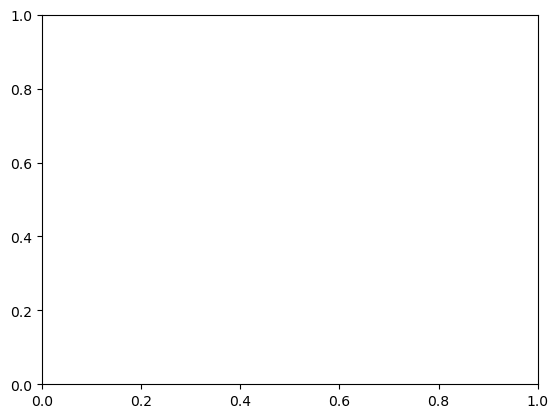

In [89]:
power = (np.abs(range_cut_padded))**2

plt.imshow(power, aspect='auto', origin='lower')

In [80]:
power.shape

(128, 1)

In [83]:
spectrogram

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(384, 195))

In [61]:
end_idx

40435600

In [15]:
import baseband
baseband.file_info(infilename)

VDIFStream information:
start_time = 2025-02-05T13:50:01.658000000
stop_time = 2025-02-05T13:54:29.018000000
sample_rate = 16.0 MHz
shape = (4277760000, 2)
format = vdif
bps = 2
complex_data = False
verify = fix
readable = True

checks:  decodable: True
         continuous: no obvious gaps

VDIFFile information:
edv = 0
number_of_frames = 267360
thread_ids = [0, 1]
number_of_framesets = 133680
frame_rate = 500.0 Hz
samples_per_frame = 32000
sample_shape = (2, 1)

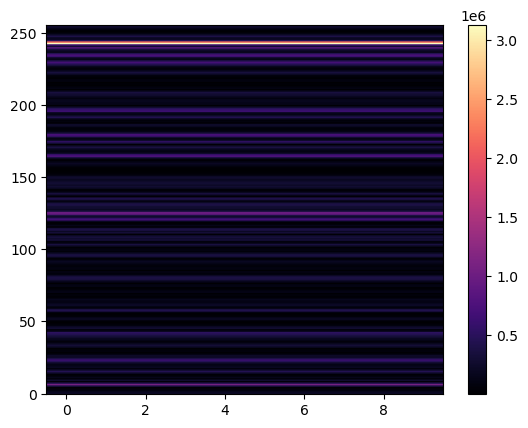

In [108]:
plt.imshow(spectrogram[:, 0:10], aspect='auto', origin='lower', cmap='magma')
plt.colorbar()
plt.show()

In [95]:
spectrogram.shape

(256, 195)

In [37]:
ts = load.timescale()
from scipy.signal.windows import tukey

cpi_jump_samples = 10000   
target = 'intelsat'
telescope = 'lovell'
tle = intelsat_tle
freqs = np.fft.fftfreq(points, d=1/samp_rate) # Used for Fourier Shift RCM correction
startoffset = 0#int(samp_rate * 100)
number_of_samples_in_whole_dataset = len(iq_samples) - startoffset
number_of_strips = 195

rcm_map = np.zeros((points, number_of_strips))

peak_history = []

print(f'Total strips to process: {number_of_strips}')
window_size = 128+zero_pad
spectrogram = np.zeros((window_size, number_of_strips))

# To try coherent processing, we want the translation-compensated matched 
# IQ data (phase history) for each pulse, stored in fast-frequency slow-time
# More below
matched_iq = np.zeros((int(samp_rate), number_of_strips), dtype=np.complex128)

for n in range(number_of_strips):
    print(f"Processing strip {n+1} of {number_of_strips}", end='\r')
    
    start_idx = startoffset + (n * cpi_jump_samples)
    end_idx = start_idx + (height * points)
    cpi_data = iq_samples[start_idx:end_idx].reshape((height, points))
    
    # Update TLE range rate for the start of this CPI
    s_offset = (start_idx / samp_rate)
    if target == 'intelsat':
        t_tle = ts.utc(2025, 2, 5, 14, 0, s_offset+1)
    elif target == 'atlas':
        t_tle = ts.utc(2026, 2, 18, 14, 50, s_offset)
    range_rate = range_finder_general(tle, t_tle, telescope)[1]
    tau_dot = range_rate / c
    
    # Create template: baseband * chirp * envelope
    # QUESTION: is this the same every loop?
    t_pulse = np.linspace(0, pri, points, endpoint=False)
    template = np.exp(1j * np.pi * alpha * t_pulse**2 * (1 - tau_dot)**2) * rect(t_pulse / (Tp * (1 + tau_dot)))
    template_fft = np.fft.fft(template)

    cdat_pc = np.zeros((height, points), dtype=complex)
    
    # Pulse Compression
    for i in range(height):
        start_sec = i * pri
        pulse_fft = np.fft.fft(cpi_data[i])
        
        # Calculating RCM Correction
        delta_tau = 2 * (range_rate * start_sec) / c     # change in range rate since beginning of CPI, converted to time delay
        rcm_shift = np.exp(1j * 2 * np.pi * freqs * delta_tau)          #applying RCM correction in the frequency domain using linear phase shift corresponding to the change in range delay over the CPI duration
        
        # Pulse Compression and RCM shift
        compressed_pulse = np.fft.ifft(pulse_fft * np.conj(template_fft) * rcm_shift)
        
        # Doppler Phase Correction
        f_d = -2 * range_rate * freq / c
        bulk_phase = np.exp(-1j * 2 * np.pi * f_d * start_sec)
        
        # applying doppler correction
        cdat_pc[i] = compressed_pulse * bulk_phase
    
    lsv, S, rsv = np.linalg.svd(cdat_pc, full_matrices=False)
    S_cleaned = S.copy()
    number_dop_com = 2
    S_cleaned[:number_dop_com] = 0.0
    cleaned_cdat_pc = np.dot(lsv * S_cleaned, rsv)
    # Average power
    cpi_power = np.mean(np.abs(cleaned_cdat_pc)**2, axis=0)
    rcm_map[:, n] = cpi_power
    
    # Extract the stable range-cut for the spectrogram
    peak_idx = np.argmax(cpi_power)
    peak_history.append(peak_idx)

    range_cut = cleaned_cdat_pc[:, peak_idx]

    # I _think_ this is also the complex phase history signal we want for 
    # coherent processing. But we might not have wanted the cleaning?
    # matched_iq[:,n] = range_cut

    #adding zero-padding
    # range_cut_padded = np.zeros(range_cut.shape[0]+zero_pad, dtype=complex)
    range_cut_padded = np.pad(range_cut, (zero_pad//2, zero_pad//2), mode='constant')

    
    print('window_size:', window_size)
    
    # Micro-Doppler (Slow-time FFT)
    # we'll just use Tukey anyway :)
    window = tukey(window_size, alpha=0.5)

    # print('window size:', len(window))
    doppler_spectrum = np.fft.fftshift(np.fft.fft(range_cut_padded * window))
    
    spectrogram[:, n] = np.abs(doppler_spectrum)**2

Total strips to process: 195
window_size: 256 1 of 195
window_size: 256 2 of 195
window_size: 256 3 of 195
window_size: 256 4 of 195
window_size: 256 5 of 195
window_size: 256 6 of 195
window_size: 256 7 of 195
window_size: 256 8 of 195
window_size: 256 9 of 195
window_size: 256 10 of 195
window_size: 256 11 of 195
window_size: 256 12 of 195
window_size: 256 13 of 195
window_size: 256 14 of 195
window_size: 256 15 of 195
window_size: 256 16 of 195
window_size: 256 17 of 195
window_size: 256 18 of 195
window_size: 256 19 of 195
window_size: 256 20 of 195
window_size: 256 21 of 195
window_size: 256 22 of 195
window_size: 256 23 of 195
window_size: 256 24 of 195
window_size: 256 25 of 195
window_size: 256 26 of 195
window_size: 256 27 of 195
window_size: 256 28 of 195
window_size: 256 29 of 195
window_size: 256 30 of 195
window_size: 256 31 of 195
window_size: 256 32 of 195
window_size: 256 33 of 195
window_size: 256 34 of 195
window_size: 256 35 of 195
window_size: 256 36 of 195
window_s

KeyboardInterrupt: 